# PPO policy performance vs. minority proportion

Companion to `analyze_ppo_by_alpha.ipynb`, but with **proportion (fraction of the
minority group) on the x-axis** while holding `alpha` fixed (default `alpha=1.0`).

For each `(method, proportion)` we auto-resolve the best-matching PPO **eval**
dataset on the Hub, score it with the same oracle definitions used in the alpha
notebook, and plot:

1. **Positiveness** and **Conciseness** (the two underlying attributes)
2. **Minority** and **Majority** oracle scores
3. **Overall performance** (proportion-weighted: `p·minority + (1-p)·majority`)
4. **Score gap** (`majority - minority`)

> Data coverage is sparse for `p != 0.2` (only `alpha=1.0` runs exist, and
> `vanilla` is missing for `p in {0.05, 0.1}`). The loader prints exactly which
> dataset was chosen for each cell so gaps / seed mismatches are visible.

In [1]:
import sys
import os
import re

ROOT = os.getcwd()
if not os.path.isdir(os.path.join(ROOT, "src")):
    ROOT = os.path.abspath(os.path.join(ROOT, ".."))
sys.path.insert(0, ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.helper.imdb_utils import load_ppo_eval

sns.set_theme(style="whitegrid", context="talk", palette="colorblind", font_scale=0.85)
METHOD_COLORS = {
    "vanilla": sns.color_palette("colorblind")[0],
    "maxmin": sns.color_palette("colorblind")[1],
    "pcgrad": sns.color_palette("colorblind")[2],
}
METHOD_LABELS = {"vanilla": "Vanilla", "maxmin": "MaxMin", "pcgrad": "PCGrad"}
METHOD_MARKERS = {"vanilla": "o", "maxmin": "s", "pcgrad": "^"}

# ---------------------------------------------------------------- configuration
USER_ID = "mxcui"
TARGET_ALPHA = 1.0          # alpha held fixed while proportion varies
DIVISOR = 256               # normalized_length = length / DIVISOR; conciseness = 1 - it
METHODS = ["vanilla", "maxmin", "pcgrad"]

# Proportions to sweep on the x-axis (only these have PPO eval datasets).
# 0.01/0.05/0.1 are older partial runs; 0.2/0.3/0.4 are the seed43 mean_kl0.1 family.
PROPORTIONS = [0.01, 0.05, 0.1, 0.2, 0.3, 0.4]


# ------------------------------------------------------ oracle score definitions
def oracle_minority(pos, nl, alpha):
    return (1 - nl) * alpha + (1 - alpha) * pos

def oracle_majority(pos, nl, alpha):
    return (1 - nl) * (1 - alpha) + alpha * pos


/root/miniconda3/envs/fairness-rlhf/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# ------------------------------------------------- discover eval datasets on Hub
# Query the Hub for all PPO eval datasets, then pick the best match per
# (method, proportion) at TARGET_ALPHA. Preference order favours the canonical
# gpt2 / mean_kl0.1 (or kl0.1) runs and seed 43 > 42, and skips ablation variants.
from huggingface_hub import HfApi

api = HfApi()
_all_eval = [
    d.id.split("/", 1)[1]
    for d in api.list_datasets(author=USER_ID)
    if "-imdb-ppo-eval-prop" in d.id
]

_EXCLUDE = ("sample", "batch", "epi3", "rlen", "rmqwen", "rmgpt2", "Qwen")

def _parse(name):
    m = re.match(
        r"(vanilla|maxmin|pcgrad)-imdb-ppo-eval-prop([0-9.]+)"
        r"(?:-alpha([0-9.]+))?-seed(\d+)(.*)$",
        name,
    )
    if not m:
        return None
    method, prop, alpha, seed, tail = m.groups()
    return {
        "name": name, "method": method, "prop": float(prop),
        "alpha": float(alpha) if alpha else None, "seed": int(seed), "tail": tail,
    }

_parsed = [p for p in (_parse(n) for n in _all_eval) if p]

def _score(rec):
    """Higher is better; used to pick a canonical dataset for a (method, prop)."""
    tail = rec["tail"]
    s = 0.0
    # kl scheme preference
    if "mean_kl0.1" in tail:
        s += 30
    elif re.search(r"(^|-)kl0\.1(-|$)", tail):
        s += 20
    elif tail in ("", "-gpt2"):
        s += 10          # bare / plain gpt2 run (e.g. prop0.05-seed42)
    # seed preference
    s += {43: 5, 42: 4}.get(rec["seed"], 1)
    # explicit alpha match beats an unlabelled (bare) dataset
    if rec["alpha"] == TARGET_ALPHA:
        s += 3
    return s

def resolve(method, prop):
    cands = [
        r for r in _parsed
        if r["method"] == method
        and abs(r["prop"] - prop) < 1e-9
        and (r["alpha"] is None or abs(r["alpha"] - TARGET_ALPHA) < 1e-9)
        and not any(x in r["tail"] for x in _EXCLUDE)
    ]
    if not cands:
        return None
    best = max(cands, key=_score)
    return f"{USER_ID}/{best['name']}"

# Show the resolution table so coverage / seed mismatches are explicit.
print(f"Resolved eval datasets (alpha={TARGET_ALPHA}):\n")
RESOLVED = {}
for method in METHODS:
    for prop in PROPORTIONS:
        rid = resolve(method, prop)
        RESOLVED[(method, prop)] = rid
        tag = rid.split("/", 1)[1] if rid else "-- MISSING --"
        print(f"  {method:8s} prop={prop:<5} -> {tag}")


Resolved eval datasets (alpha=1.0):

  vanilla  prop=0.01  -> vanilla-imdb-ppo-eval-prop0.01-alpha1.0-seed43-mean_kl0.1-gpt2
  vanilla  prop=0.05  -> -- MISSING --
  vanilla  prop=0.1   -> -- MISSING --
  vanilla  prop=0.2   -> vanilla-imdb-ppo-eval-prop0.2-alpha1.0-seed43-mean_kl0.1-gpt2
  vanilla  prop=0.3   -> vanilla-imdb-ppo-eval-prop0.3-alpha1.0-seed43-mean_kl0.1-gpt2
  vanilla  prop=0.4   -> vanilla-imdb-ppo-eval-prop0.4-alpha1.0-seed43-mean_kl0.1-gpt2
  maxmin   prop=0.01  -> maxmin-imdb-ppo-eval-prop0.01-alpha1.0-seed43-mean_kl0.1-gpt2
  maxmin   prop=0.05  -> maxmin-imdb-ppo-eval-prop0.05-seed42
  maxmin   prop=0.1   -> maxmin-imdb-ppo-eval-prop0.1-seed42
  maxmin   prop=0.2   -> maxmin-imdb-ppo-eval-prop0.2-alpha1.0-seed43-mean_kl0.1-gpt2
  maxmin   prop=0.3   -> maxmin-imdb-ppo-eval-prop0.3-alpha1.0-seed43-mean_kl0.1-gpt2
  maxmin   prop=0.4   -> maxmin-imdb-ppo-eval-prop0.4-alpha1.0-seed43-mean_kl0.1-gpt2
  pcgrad   prop=0.01  -> -- MISSING --
  pcgrad   prop=0.05  -> -- M

In [3]:
# ------------------------------------------------------- load + score datasets
# Datasets use two storage conventions for `positiveness`:
#   * scalar probability in [0, 1]              (seed43 mean_kl0.1 family)
#   * raw 2-logit array [neg, pos]              (bare seed42 family, e.g. prop0.05/0.1)
# Normalise both to a scalar P(positive). `conciseness` is (re)computed uniformly
# from `length` with DIVISOR so every proportion is on the same definition.
def to_prob(v):
    a = np.asarray(v, dtype=float)
    if a.ndim == 0:
        return float(a)
    if a.size == 1:
        return float(a.reshape(-1)[0])
    if a.size == 2:                       # [neg_logit, pos_logit] -> softmax pos
        e = np.exp(a - a.max())
        return float((e / e.sum())[1])
    return float(a.reshape(-1)[-1])

results = {}   # (method, prop) -> scored DataFrame

for (method, prop), repo_id in RESOLVED.items():
    if repo_id is None:
        continue
    try:
        df = load_ppo_eval(repo_id).to_pandas()
    except Exception as e:
        print(f"Could not load {method} prop={prop} ({repo_id}): {e}")
        continue

    if "positiveness" not in df.columns or "length" not in df.columns:
        print(f"Skipping {method} prop={prop}: missing scored columns (positiveness/length)")
        continue

    df["positiveness"] = df["positiveness"].map(to_prob)
    df["normalized_length"] = np.clip(df["length"].astype(float) / DIVISOR, 0, 1)
    df["conciseness"] = 1 - df["normalized_length"]
    df["minority_score"] = oracle_minority(df["positiveness"], df["normalized_length"], TARGET_ALPHA)
    df["majority_score"] = oracle_majority(df["positiveness"], df["normalized_length"], TARGET_ALPHA)
    # overall performance weights each point by ITS OWN proportion
    df["overall_performance"] = prop * df["minority_score"] + (1 - prop) * df["majority_score"]
    df["score_gap"] = df["majority_score"] - df["minority_score"]
    results[(method, prop)] = df

# ------------------------------------------------------------- aggregate to mean
metrics = [
    "positiveness", "conciseness", "minority_score", "majority_score",
    "overall_performance", "score_gap",
]
rows = []
for (method, prop), df in results.items():
    row = {"method": method, "proportion": prop}
    for metric in metrics:
        row[metric] = df[metric].mean()
        row[f"{metric}_std"] = df[metric].std()
    rows.append(row)

df_agg = pd.DataFrame(rows).sort_values(["method", "proportion"]).reset_index(drop=True)
df_agg


Generating train split:   0%|          | 0/24872 [00:00<?, ? examples/s]

Generating train split: 100%|██████████| 24872/24872 [00:00<00:00, 31266.48 examples/s]

Generating train split: 100%|██████████| 24872/24872 [00:02<00:00, 9315.49 examples/s] 

Generating train split:   0%|          | 0/24872 [00:00<?, ? examples/s]

Generating train split: 100%|██████████| 24872/24872 [00:00<00:00, 163045.72 examples/s]

Generating train split: 100%|██████████| 24872/24872 [00:00<00:00, 135355.25 examples/s]

... (3 outputs left out)

Generating train split:   0%|          | 0/24872 [00:00<?, ? examples/s]

Generating train split: 100%|██████████| 24872/24872 [00:00<00:00, 155516.43 examples/s]

Generating train split: 100%|██████████| 24872/24872 [00:02<00:00, 9445.30 examples/s]  

,method,proportion,positiveness,positiveness_std,conciseness,conciseness_std,minority_score,minority_score_std,majority_score,majority_score_std,overall_performance,overall_performance_std,score_gap,score_gap_std
0,maxmin,0.01,0.698616,0.331895,0.953868,0.013079,0.953868,0.013079,0.698616,0.331895,0.701169,0.328563,-0.255252,0.333455
1,maxmin,0.05,0.962416,0.142486,0.944139,0.017455,0.944139,0.017455,0.962416,0.142486,0.961502,0.135298,0.018278,0.144868
2,maxmin,0.10,0.930867,0.197002,0.952416,0.013825,0.952416,0.013825,0.930867,0.197002,0.933022,0.177205,-0.021548,0.198506
3,maxmin,0.20,0.692883,0.325629,0.969858,0.009130,0.969858,0.009130,0.692883,0.325629,0.748278,0.260417,-0.276975,0.326224
4,maxmin,0.30,0.712340,0.323873,0.132878,0.249936,0.132878,0.249936,0.712340,0.323873,0.538501,0.242553,0.579462,0.398414
5,maxmin,0.40,0.708917,0.326039,0.121691,0.240968,0.121691,0.240968,0.708917,0.326039,0.474026,0.222866,0.587225,0.394429
6,pcgrad,0.20,0.902645,0.236139,0.946378,0.022061,0.946378,0.022061,0.902645,0.236139,0.911391,0.188540,-0.043733,0.239258
7,pcgrad,0.30,0.709983,0.324710,0.125350,0.244116,0.125350,0.244116,0.709983,0.324710,0.534593,0.241839,0.584633,0.397596
8,pcgrad,0.40,0.714362,0.323603,0.129308,0.245700,0.129308,0.245700,0.714362,0.323603,0.480340,0.222781,0.585054,0.394480
9,vanilla,0.01,0.989787,0.036839,0.064787,0.163491,0.064787,0.163491,0.989787,0.036839,0.980537,0.036496,0.925000,0.167835


In [4]:
# ---------------------------------------------------------- shared plot helper
def plot_metric(ax, metric, title=None, ylabel=None, err_scale=0.5, methods=METHODS):
    std_col = f"{metric}_std"
    for method in methods:
        sub = df_agg[df_agg["method"] == method].sort_values("proportion")
        if not len(sub):
            continue
        yerr = err_scale * sub[std_col].fillna(0)
        ax.errorbar(
            sub["proportion"], sub[metric], yerr=yerr,
            fmt=f"{METHOD_MARKERS[method]}-", color=METHOD_COLORS[method],
            label=METHOD_LABELS[method], capsize=4,
            linewidth=3, markersize=8, markerfacecolor="white", markeredgewidth=1.5,
        )
    ax.set_xscale("log")
    ax.set_xticks(PROPORTIONS)
    ax.get_xaxis().set_major_formatter(plt.matplotlib.ticker.ScalarFormatter())
    ax.set_xlabel("Minority proportion")
    if ylabel:
        ax.set_ylabel(ylabel)
    if title is not None:
        ax.set_title(title, fontweight="semibold", fontsize=16)
    ax.legend(title="Method", frameon=True)
    sns.despine(ax=ax)


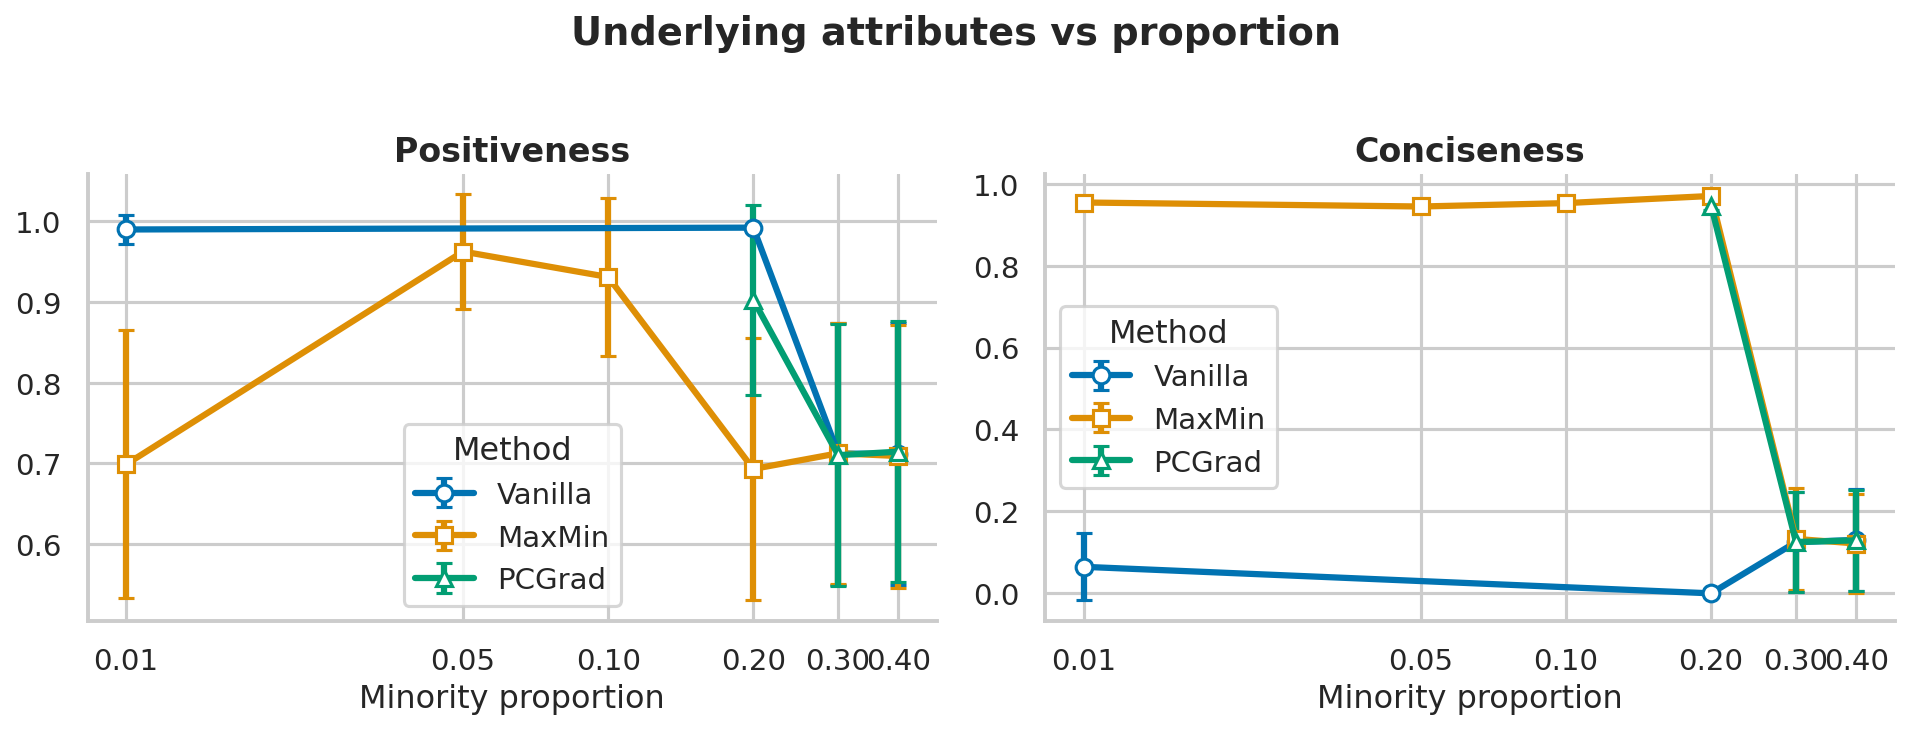

In [5]:
# 1. Positiveness & Conciseness vs proportion
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), dpi=150)
plot_metric(axes[0], "positiveness", title="Positiveness")
plot_metric(axes[1], "conciseness", title="Conciseness")
fig.suptitle("Underlying attributes vs proportion", y=1.02, fontweight="semibold")
plt.tight_layout()
plt.savefig("ppo_by_prop_attributes.pdf", format="pdf", bbox_inches="tight", dpi=300)
plt.show()


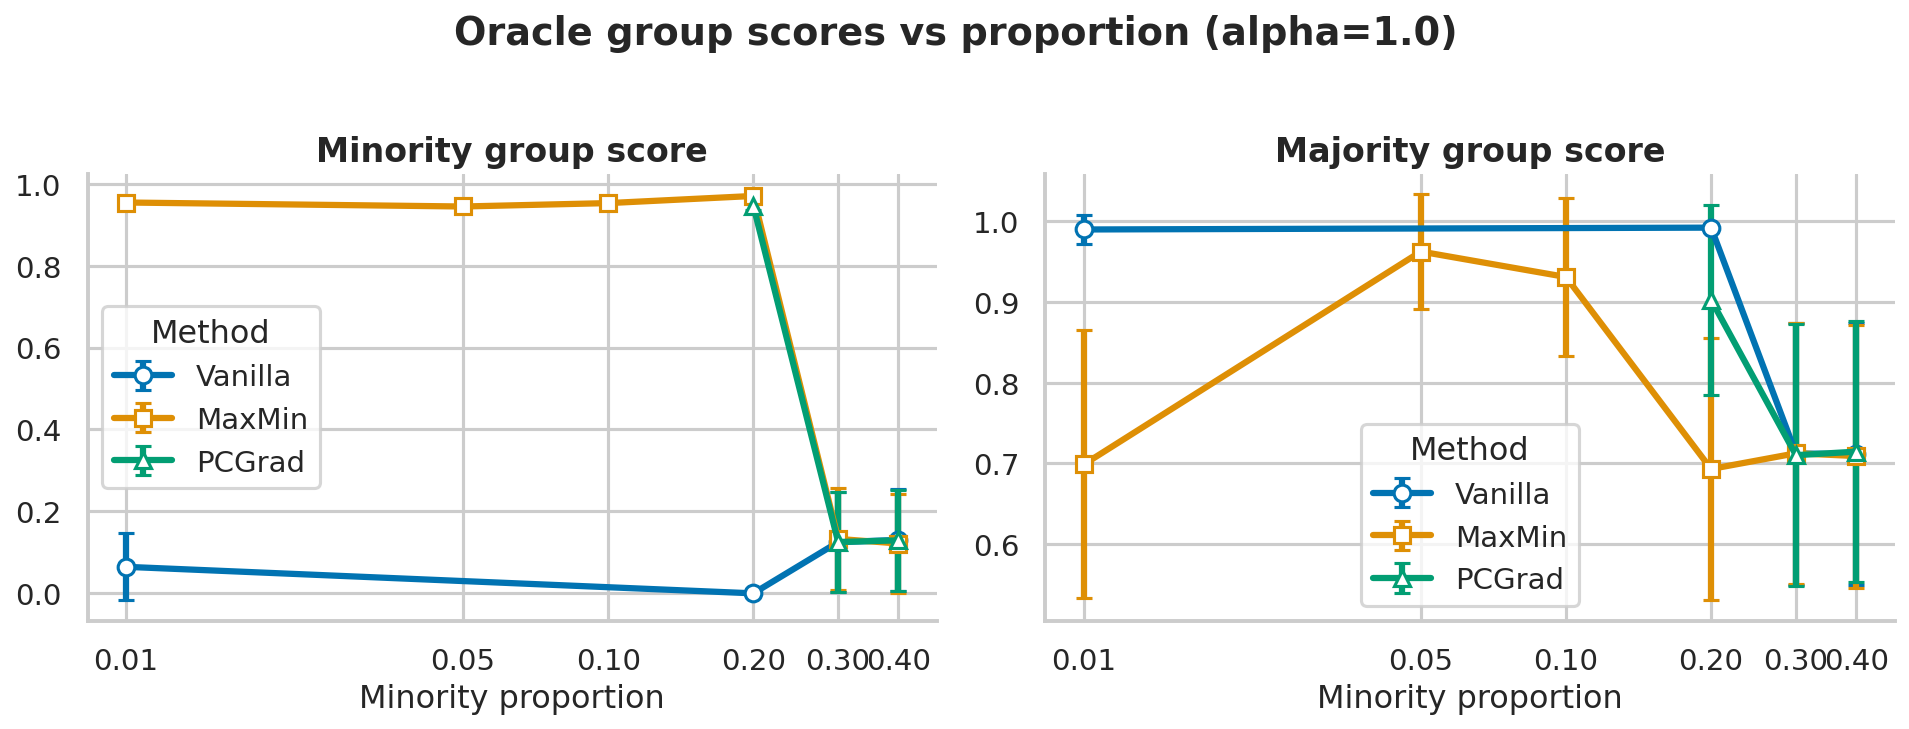

In [6]:
# 2. Minority & Majority oracle scores vs proportion
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), dpi=150)
plot_metric(axes[0], "minority_score", title="Minority group score")
plot_metric(axes[1], "majority_score", title="Majority group score")
fig.suptitle(f"Oracle group scores vs proportion (alpha={TARGET_ALPHA})", y=1.02, fontweight="semibold")
plt.tight_layout()
plt.savefig("ppo_by_prop_group_scores.pdf", format="pdf", bbox_inches="tight", dpi=300)
plt.show()


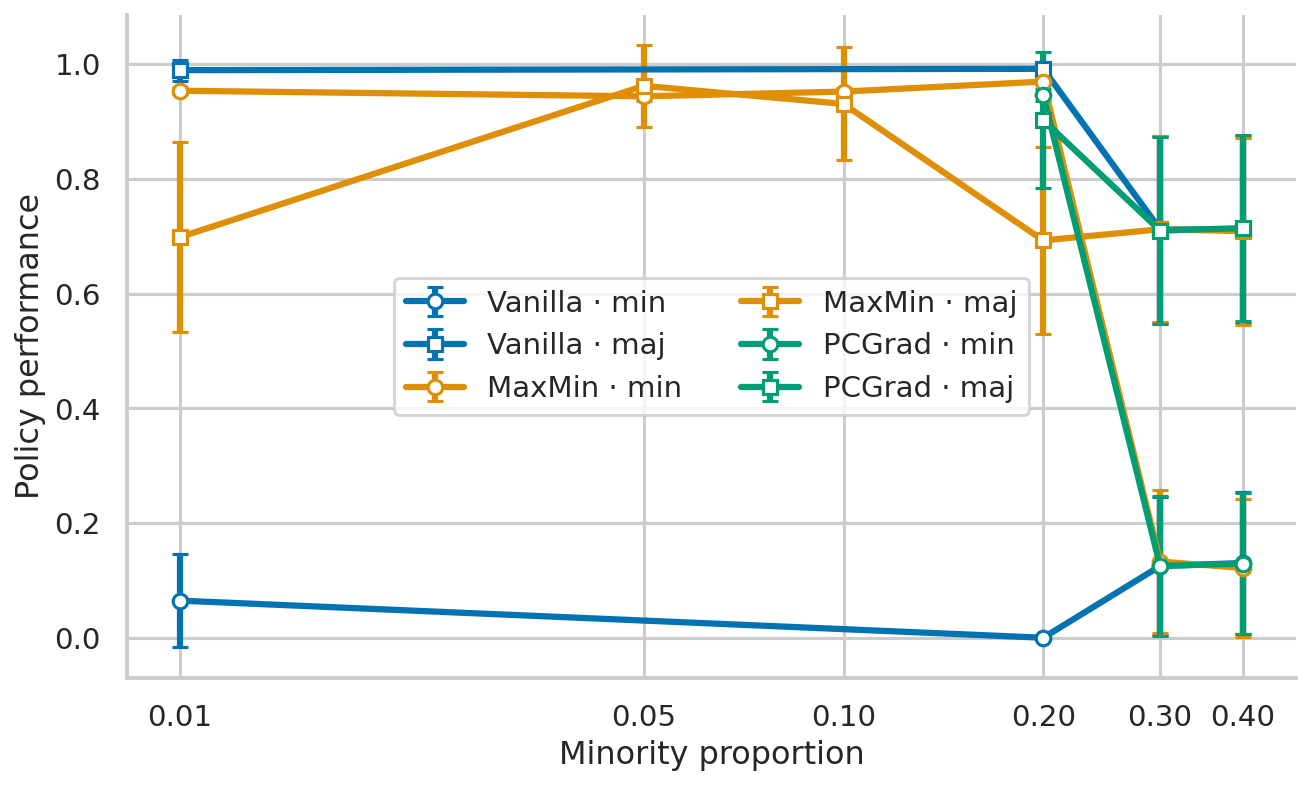

In [7]:
# 2b. Minority vs majority on a single axis (per method)
fig, ax = plt.subplots(figsize=(9, 5.5), dpi=150)
series = []
for _m in METHODS:
    _lbl = METHOD_LABELS.get(_m, _m.capitalize())
    series.append((_m, "minority_score", "o", f"{_lbl} \u00b7 min"))
    series.append((_m, "majority_score", "s", f"{_lbl} \u00b7 maj"))
for method, metric, marker, label in series:
    sub = df_agg[df_agg["method"] == method].sort_values("proportion")
    if not len(sub):
        continue
    yerr = 0.5 * sub[f"{metric}_std"].fillna(0)
    ax.errorbar(
        sub["proportion"], sub[metric], yerr=yerr,
        fmt=f"{marker}-", color=METHOD_COLORS[method], label=label, capsize=4,
        linewidth=3, markersize=7, markerfacecolor="white", markeredgewidth=1.5,
    )
ax.set_xscale("log")
ax.set_xticks(PROPORTIONS)
ax.get_xaxis().set_major_formatter(plt.matplotlib.ticker.ScalarFormatter())
ax.set_xlabel("Minority proportion")
ax.set_ylabel("Policy performance")
ax.legend(frameon=True, ncol=2)
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig("ppo_by_prop_minority_majority.pdf", format="pdf", bbox_inches="tight", dpi=300)
plt.show()


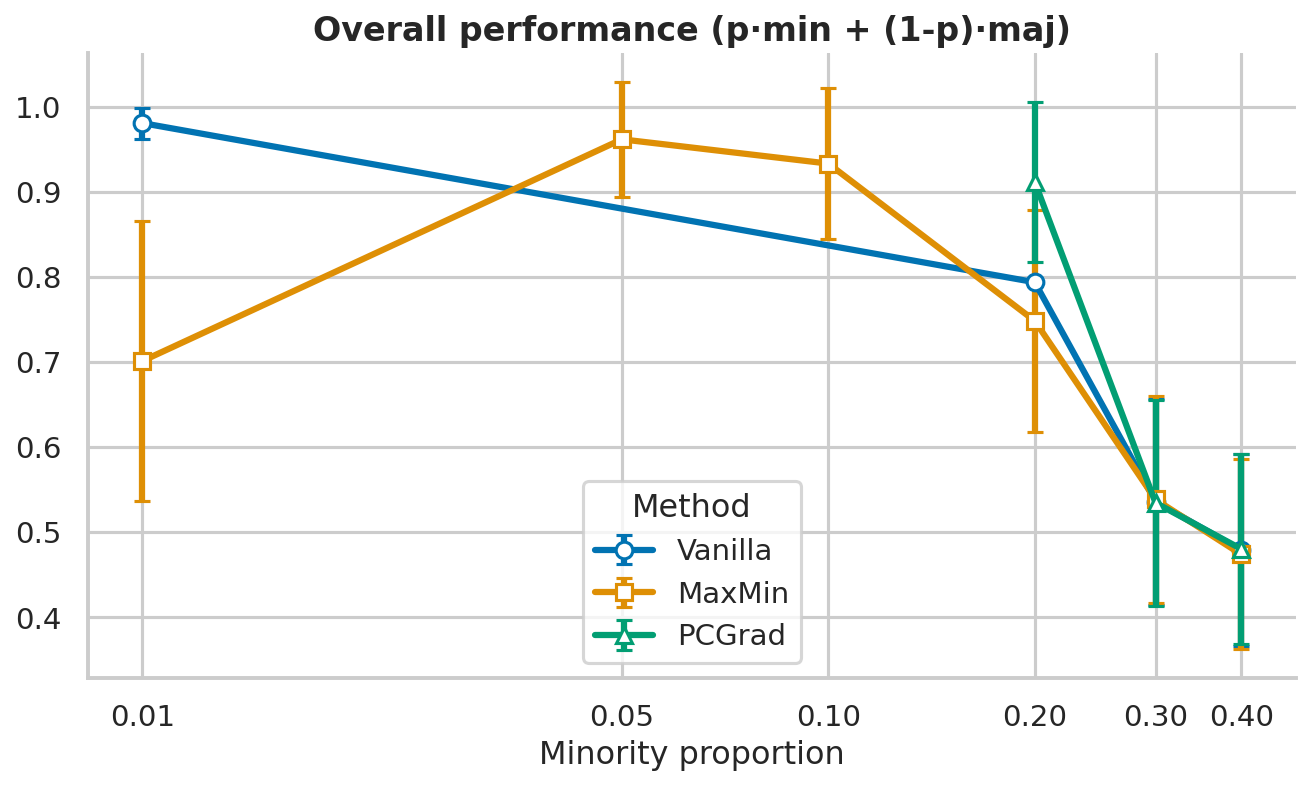

In [8]:
# 3. Overall performance vs proportion
fig, ax = plt.subplots(figsize=(9, 5.5), dpi=150)
plot_metric(ax, "overall_performance",
            title="Overall performance (p\u00b7min + (1-p)\u00b7maj)")
plt.tight_layout()
plt.savefig("ppo_by_prop_overall.pdf", format="pdf", bbox_inches="tight", dpi=300)
plt.show()


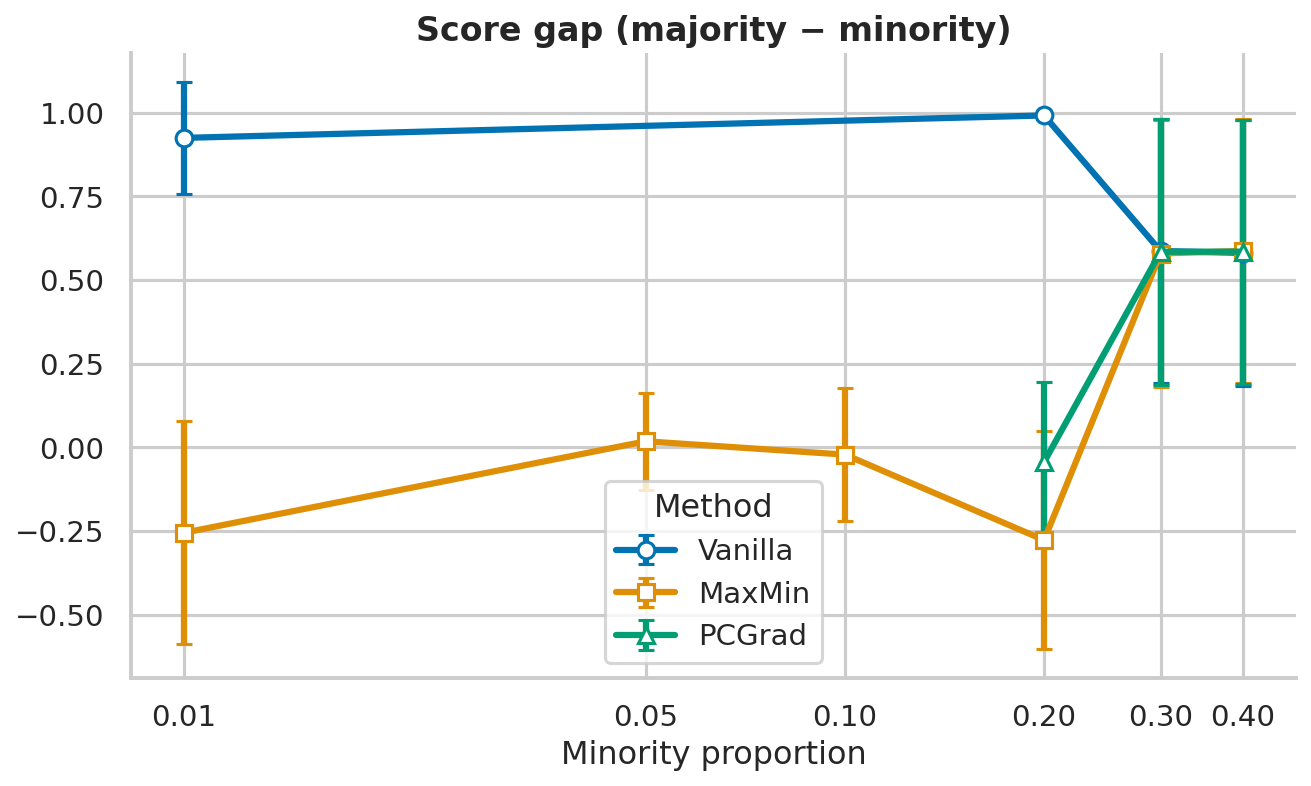

In [9]:
# 4. Score gap (majority - minority) vs proportion
fig, ax = plt.subplots(figsize=(9, 5.5), dpi=150)
ax.axhline(0, color="gray", linestyle=":", linewidth=1.2, zorder=0)
plot_metric(ax, "score_gap", title="Score gap (majority \u2212 minority)", err_scale=1.0)
plt.tight_layout()
plt.savefig("ppo_by_prop_gap.pdf", format="pdf", bbox_inches="tight", dpi=300)
plt.show()
